# Lesson 8 — From a Chain of Operations to the First Training Loop

[Course plan](../../README.md) · [Previous lesson](lesson-07.ipynb) · [Русский](../ru/lesson-08.ipynb) · [Next: a whole image](lesson-09.ipynb)

In the previous lesson, we watched the loss change after a small parameter movement. Two extra evaluations are cheap enough for one center. Soon an image will contain dozens of spots, each with several numbers of its own. Rebuilding the entire image separately for each number becomes expensive.

Yet the image already comes from familiar operations: subtraction, division, multiplication, and the exponential. We can keep track of those operations, then walk through them backward. That gives a gradient, and the gradient gives the next training step.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import math
import numpy as np
import torch
from IPython.display import display

course_root = next(folder for folder in [Path.cwd(), *Path.cwd().parents]
                   if (folder / "training_math.py").is_file())
if str(course_root) not in sys.path:
    sys.path.insert(0, str(course_root))

from training_math import (chain_example, autograd_check, fit_one_gaussian,
                           make_target, initialize, render_torch, projected_step,
                           fit_image, parameters_scene, load_image, small_cpu_work)
from training_demos import (chain_figure, learning_figure, autograd_lab,
                            demo_fit, fitting_figure, detail_figure, fitting_lab)
LANG = 'en'

## 1. The Bell Curve Starts Moving on Its Own

The dark curve is a target with center $1.5$ and scale $1$. The blue curve is our attempt. Its scale is the same, but its initial center is $-1$. Only the center changes during training; height and scale remain fixed for now.

The “Step” field shows the state after that many updates. Beside the curves are the loss and the center's path. A zero step size produces no movement. An excessive step can jump across the desired position. This experiment uses the whole curve; the numerical explanation below starts with just one sample.

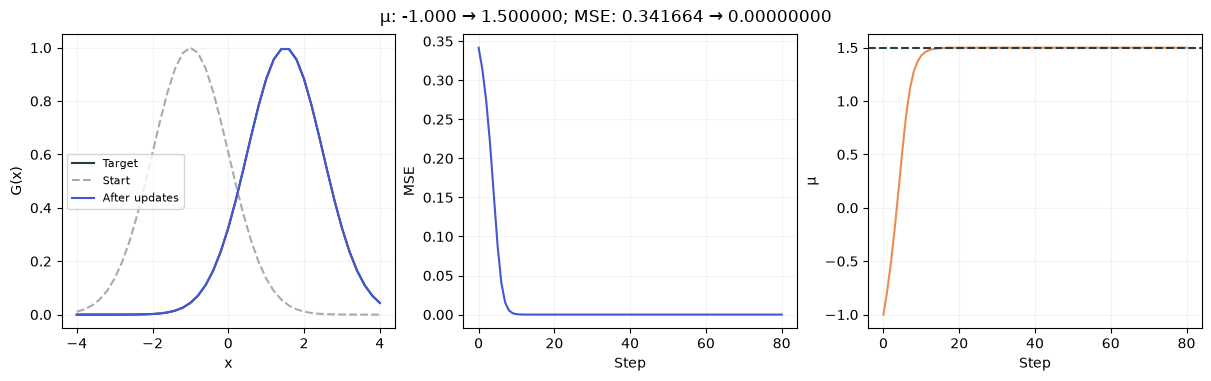

In [2]:
display(learning_figure(language=LANG))
display(autograd_lab(language=LANG))

## 2. One Calculation, Seven Short Operations

We take sample position $x=1$, center $\mu=0$, and scale $\sigma=1$. The target value at this position is $y=0.8$. Here $y$ means the desired weight, not an image's vertical coordinate. Weights are dimensionless. Positions and scale use the same arbitrary distance unit.

Our Gaussian produces $G$. The residual $r$ is our value minus the target. The loss $L$ is its square. There is only one measurement, so there is nothing to average yet.

| Operation | Substitution | Result |
|---|---|---|
| $d=x-\mu$ | $1-0$ | $1$ |
| $u=d/\sigma$ | $1/1$ | $1$ |
| $q=u\cdot u$ | $1\cdot1$ | $1$ |
| $t=-q/2$ | $-1/2$ | $-0.5$ |
| $G=\exp(t)$ | $\exp(-0.5)$ | $0.606530660$ |
| $r=G-y$ | $0.606530660-0.8$ | $-0.193469340$ |
| $L=r\cdot r$ | $(-0.193469340)^2$ | $0.037430386$ |

The path is center → displacement → relative displacement → square → exponent → weight → residual → loss. This is a **computation graph**. Here it resembles a chain. In a larger program, paths can split and join again.

The desired weight is greater than ours. Moving the center right brings $x=1$ closer to the peak, raising its weight. Near $\mu=0$, a rightward movement should therefore reduce the loss. The gradient will check this intuition numerically.

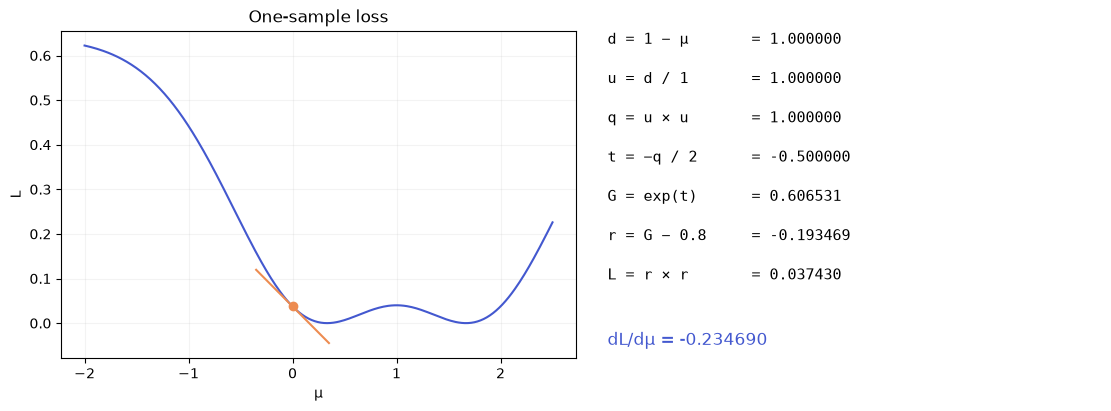

d 1.0
u 1.0
q 1.0
t -0.5
weight 0.6065306597126334
residual -0.19346934028736662
loss 0.03743038563122886
local [-0.38693868057473324, 0.6065306597126334, -0.5, 2.0, 1.0, -1.0]
gradient -0.23469017319732888


In [3]:
display(chain_figure(language=LANG))
for name, value in chain_example().items():
    print(name, value)

## 3. Each Operation Has a Small Local Slope

The notation $dL/dr$ means “the derivative of loss with respect to residual.” The $d$ beside $L$ and $r$ belongs to derivative notation; it is not our displacement from the table. Its meaning is: a small residual change $\Delta r$ produces a loss change of approximately $(dL/dr)\Delta r$.

We start with a square. Its input is $a$ and a small change is $h$, with $h\ne0$:

$$
\frac{(a+h)^2-a^2}{h}
=\frac{a^2+2ah+h^2-a^2}{h}
=2a+h.
$$

We expanded the brackets, canceled equal squares, and divided the remaining terms by $h$. As $h$ gets smaller, its extra contribution tends to zero and the slope tends to $2a$. Thus $L=r^2$ has slope $2r$, while $q=u^2$ has slope $2u$. In our example these are $-0.386938681$ and $2$.

The other simple operations follow directly from changing their inputs:

- In $r=G-y$, the target $y$ is fixed. Adding $h$ to $G$ adds the same amount to $r$: slope $1$.
- In $t=-q/2$, adding $h$ to $q$ changes $t$ by $-h/2$: slope $-1/2$.
- In $u=d/\sigma$, scale is fixed. Adding $h$ to $d$ changes $u$ by $h/\sigma$: slope $1/\sigma=1$.
- In $d=x-\mu$, the sample position $x$ is fixed. Adding $h$ to the center subtracts $h$ from the displacement: slope $-1$.

The exponential is the remaining operation. Its special property is that its slope at $t$ equals its own value $\exp(t)$. This is not true of arbitrary curves. For the exponential:

$$
\frac{\exp(t+h)-\exp(t)}{h}
=\exp(t)\frac{\exp(h)-1}{h}.
$$

We used $\exp(t+h)=\exp(t)\exp(h)$ and factored out a common term. The ratio on the right approaches $1$ as $h$ approaches zero: about $1.051709$ for $h=0.1$, $1.005017$ for $0.01$, and $1.000500$ for $0.001$. The limit leaves $\exp(t)$. At $t=-0.5$, this local slope is $0.606530660$.

This property of the natural exponential can also be derived from its infinite-series definition. Here the useful point is the change it describes, checked with small shifts. The code uses derivatives of the actual operations, not these approximate ratios.

In [4]:
for h in [0.1, 0.01, 0.001, 0.0001]:
    print(f"h={h:g}: expm1(h)/h = {math.expm1(h) / h:.9f}")

h=0.1: expm1(h)/h = 1.051709181
h=0.01: expm1(h)/h = 1.005016708
h=0.001: expm1(h)/h = 1.000500167
h=0.0001: expm1(h)/h = 1.000050002


## 4. Why the Slopes Multiply

If one operation turns a small input change into a change twice as large, and the next scales it by another factor of three, the whole path scales it by roughly six. The numbers $2$ and $3$ are local slopes. Successive changes give $\Delta b\approx2\Delta a$ and $\Delta c\approx3\Delta b\approx6\Delta a$.

This is the **chain rule**. The approximation sign applies to finite changes. In the limit of an infinitesimal change, derivatives satisfy an exact equality. The rule describes a smooth neighborhood, not the exact result of a large jump.

We can walk backward from loss to center. Initially, the sensitivity of $L$ to itself is $1$. Each local slope then multiplies the sensitivity accumulated so far:

| Backward transition | Factor | Accumulated sensitivity |
|---|---|---|
| $L\to r$ | $2r=-0.386938681$ | $-0.386938681$ |
| $r\to G$ | $1$ | $-0.386938681$ |
| $G\to t$ | $G=0.606530660$ | $-0.234690173$ |
| $t\to q$ | $-0.5$ | $0.117345087$ |
| $q\to u$ | $2u=2$ | $0.234690173$ |
| $u\to d$ | $1/\sigma=1$ | $0.234690173$ |
| $d\to\mu$ | $-1$ | $-0.234690173$ |

Written compactly:

$$
\frac{dL}{d\mu}
=\frac{dL}{dr}\frac{dr}{dG}\frac{dG}{dt}
 \frac{dt}{dq}\frac{dq}{du}\frac{du}{dd}\frac{dd}{d\mu}
=2(G-y)G\frac{x-\mu}{\sigma^2}.
$$

The final fraction comes from multiplying $(-1/2)\cdot2u\cdot(1/\sigma)\cdot(-1)$, which gives $u/\sigma$. Since $u=(x-\mu)/\sigma$, one more division by scale gives $(x-\mu)/\sigma^2$. Every part of the compact formula already appeared in the table.

The gradient is negative. A small positive center movement reduces the loss. For example, the linear estimate for $\Delta\mu=0.01$ is a loss change of $-0.234690173\cdot0.01=-0.002346902$. This is the change, not the new loss: the estimated new loss is $0.037430386-0.002346902=0.035083484$. Direct evaluation differs slightly because the slope changes along the way.

In [5]:
start = chain_example()
shift = 0.01
print("linear estimate:", start["loss"] + start["gradient"] * shift)
print("direct evaluation:", chain_example(mu=shift)["loss"])

linear estimate: 0.03508348389925557
direct evaluation: 0.035120347809244036


## 5. The Same Work Done by PyTorch

A **tensor** here is a number, a vector, or a rectangular array of numbers. The first line creates a one-number tensor: a scalar. `requires_grad=True` marks a value whose gradient is needed. The flag does not train it or move it automatically.

`float64` stores roughly 15–16 significant decimal digits. This is useful for small checks: rounding interferes less with comparisons against tiny shifts. Larger models often use lower precision, but that is a separate choice.

PyTorch builds a graph during the calculation. Calling `backward()` walks through it backward and adds contributions to `mu.grad`. The `item()` method extracts an ordinary number for display only. Extracting a number in the middle of the computation and continuing with it would break its connection to the graph.

In [6]:
mu = torch.tensor(0.0, dtype=torch.float64, requires_grad=True)
x, sigma, target = 1.0, 1.0, 0.8
d = x - mu
u = d / sigma
q = u * u
t = -q / 2
weight = torch.exp(t)
residual = weight - target
loss = residual * residual
loss.backward()
print(f"G = {weight.item():.9f}")
print(f"L = {loss.item():.9f}")
print(f"dL/dmu = {mu.grad.item():.9f}")
assert abs(mu.grad.item() - chain_example()["gradient"]) < 1e-12

G = 0.606530660
L = 0.037430386
dL/dmu = -0.234690173


When one parameter is used several times, its contributions are **added**. In $q=u\cdot u$, the value $u$ reaches the multiplication by two paths. Each path contributes a factor of $u$, giving $u+u=2u$. Likewise, a center shared by many pixels receives a contribution from every pixel.

This is **automatic differentiation**, or autograd. It does not guess derivatives from a picture, perturb each parameter numerically, or solve training by itself. It applies known rules to the operations that were executed. The gradient belongs to the current values. After parameters change, the computation graph is built again.

The behavior of `requires_grad`, `backward`, and gradient accumulation is described in the [official introduction to autograd](https://docs.pytorch.org/tutorials/beginner/blitz/autograd_tutorial.html).

## 6. An Independent Gradient Check

The previous lesson left us another way to measure slope: evaluate loss a little to the left and right. For a center,

$$
g_h=\frac{L(\mu+h)-L(\mu-h)}{2h}.
$$

The numerator is the loss change between two points. The denominator is their separation: from $\mu-h$ to $\mu+h$ is exactly $2h$. Here $h>0$ has coordinate units, while $g_h$ has loss units per coordinate unit. Autograd should give a similar number on a smooth part of the curve.

A large $h$ spans an appreciably curved section. An excessively small $h$ subtracts nearly equal rounded numbers. Thus “smaller” does not always mean “more accurate.” Checking several shift sizes is more useful than a single accidental agreement.

In [7]:
for h in [0.1, 0.01, 0.001, 1e-5, 1e-7, 1e-9]:
    check = autograd_check(epsilon=h)
    print(f"h={h:.0e}  autograd={check['autograd']:.12f}  finite={check['finite_difference']:.12f}")
assert abs(autograd_check()["autograd"] - autograd_check()["finite_difference"]) < 1e-8

h=1e-01  autograd=-0.234690173197  finite=-0.233915139785
h=1e-02  autograd=-0.234690173197  finite=-0.234682350922
h=1e-03  autograd=-0.234690173197  finite=-0.234690094967
h=1e-05  autograd=-0.234690173197  finite=-0.234690173189
h=1e-07  autograd=-0.234690173197  finite=-0.234690173163
h=1e-09  autograd=-0.234690173197  finite=-0.234690173545


## 7. A Gradient Becomes One Step

The update from the previous lesson was

$$
\mu_{\text{new}}=\mu_{\text{old}}-\eta\frac{dL}{d\mu}.
$$

$\eta$ is the step size, or learning rate. It is not the actual movement distance: that also depends on the gradient. For our one-sample example, we take $\eta=0.5$:

$$
\mu_{\text{new}}=0-0.5\cdot(-0.234690173)=0.117345087.
$$

The two minus signs produce a plus. The center moves right, just as expected. In terms of units, $dL/d\mu$ has “loss per coordinate” units, and $\eta$ converts that into a coordinate displacement. Our numerical units are fixed by the chosen scales; changing coordinate or loss scales calls for reconsidering the step size.

`torch.no_grad()` turns off graph recording **while the parameter is updated**. Autograd is needed again for the next loss evaluation. After the update, `mu.grad = None` removes the old gradient: the next backward pass should measure the direction at the new location rather than add it to yesterday's direction.

In [8]:
old_loss = loss.item()
with torch.no_grad():
    mu -= 0.5 * mu.grad
mu.grad = None
new_weight = torch.exp(-0.5 * (1 - mu).square())
new_loss = (new_weight - 0.8).square()
print("center after one update:", mu.item())
print("loss before / after:", old_loss, new_loss.item())
assert new_loss.item() < old_loss

center after one update: 0.11734508659866444
loss before / after: 0.03743038563122886 0.015038485966392083


## 8. Now the Whole Curve

One sample cannot uniquely determine the center. At $x=1$, the same weight $0.8$ can come from centers on either side of that point. Their distances are equal. This is a limitation of the observations, not an autograd bug.

We take $41$ positions from $-4$ to $4$, inclusive, spaced by $0.2$. At every position, we generate the target with one Gaussian centered at $1.5$ and scaled by $1$. Our model still has only one adjustable center.

$$
L=\frac{1}{M}\sum_{j=1}^{M}(G_j-y_j)^2,\qquad M=41.
$$

The index $j$ identifies a sample, not a coordinate. $G_j$ is our value there; $y_j$ is the target value. The $\sum$ sign means “add the expression for every index from $1$ through $M$.” Dividing by $M$ turns the sum of squares into a mean square. For three residuals $0.2,-0.1,0.3$, it is $(0.04+0.01+0.09)/3=0.0466667$.

In the backward pass, each square contributes a term multiplied by $1/M$. Contributions to the shared center add up:

$$
\frac{dL}{d\mu}=\frac{1}{M}\sum_{j=1}^{M}
2(G_j-y_j)G_j\frac{x_j-\mu}{\sigma^2}.
$$

This is the familiar chain repeated at each sample. If there were two samples with contributions $-0.2$ and $0.1$, their mean gradient would be $(-0.2+0.1)/2=-0.05$. Samples do not vote for separate centers: their effects combine into the update of one shared parameter.

step= 0  mu=-1.0000000  MSE=0.341664106
step=20  mu=1.4997426  MSE=0.000000007
step=40  mu=1.5000000  MSE=0.000000000
step=60  mu=1.5000000  MSE=0.000000000
step=80  mu=1.5000000  MSE=0.000000000


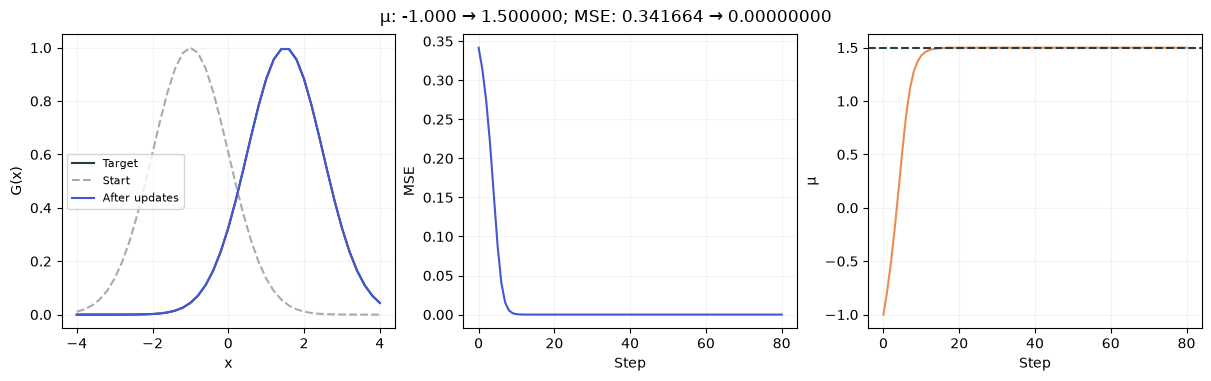

In [9]:
x = torch.linspace(-4, 4, 41, dtype=torch.float64)
target_curve = torch.exp(-0.5 * (x - 1.5).square())
center = torch.tensor(-1.0, dtype=torch.float64, requires_grad=True)
optimizer = torch.optim.SGD([center], lr=2.0)
trace = []
for step in range(81):
    optimizer.zero_grad(set_to_none=True)
    predicted = torch.exp(-0.5 * (x - center).square())
    mse = (predicted - target_curve).square().mean()
    trace.append((step, center.item(), mse.item()))
    if step == 80:
        break
    mse.backward()
    optimizer.step()

for step, position, error in trace[::20]:
    print(f"step={step:2d}  mu={position:.7f}  MSE={error:.9f}")
assert trace[-1][2] < trace[0][2] * 1e-6
display(learning_figure(language=LANG))

`torch.optim.SGD` stores the adjustable tensors and the learning rate. With `momentum=0`, the default used here, `optimizer.step()` performs the familiar “parameter minus learning rate times gradient.” The update already happens without graph recording, so it needs no extra `no_grad()` wrapper.

`zero_grad(set_to_none=True)` does for the whole list what `mu.grad = None` did earlier. The order matters: remove old gradients → compute a new prediction → measure loss → compute new gradients → update parameters. Loss is evaluated once more at the final state without another update.

SGD includes “stochastic” in its name, but there is no random sampling here: every step uses all $41$ observations. This is ordinary full-batch gradient descent on a small problem. PyTorch exposes it through the same class. Its parameters are listed in the [SGD documentation](https://docs.pytorch.org/docs/stable/generated/torch.optim.SGD.html).

Autograd neither guarantees that every step lowers loss nor chooses a step size. If the center is far outside the observed region, the Gaussian is almost invisible everywhere; the exponential and its gradient are both tiny. Even a correct gradient may barely move the model there. Reconstruction also depends on initialization.

## 9. A Few Experiments, Explained

**First, one step.** From initial center $-1$ with $\eta=2$, loss should fall and the center should move right. It need not reach $1.5$ in a single update.

**Then, step size.** At $\eta=0$, every state is identical. Increasing $\eta$ may initially reach the target faster, then produce overshooting and rising loss. The same large step can behave differently at the start and near a minimum because curvature changes.

**Finally, initialization.** A center at $-3$ starts farther from the target than one at $-1$. Equal update counts need not produce equal quality.

<details>
<summary>Explanation: why gradients should not carry over between steps</summary>

Suppose the first gradient was $-0.2$, and after the update the new gradient is $-0.1$. Without clearing it, `.grad` accumulates $-0.3$. At $\eta=1$, the next movement becomes $+0.3$ instead of $+0.1$. That is a different algorithm, not the one we derived. Deliberate accumulation can help with large datasets, but here we need the gradient of the current full loss.

</details>

<details>
<summary>Explanation: one weight, two centers</summary>

At $x=1$, centers $\mu=0$ and $\mu=2$ are equally far away: displacements $1$ and $-1$ have equal squares. Both give $\exp(-0.5)$. The target weight $0.8$ also has two possible centers, approximately $0.331953$ and $1.668047$. One observation cannot choose between them. Additional curve samples supply additional constraints.

</details>

<details>
<summary>Explanation: why finite differences still matter with autograd</summary>

Autograd correctly differentiates the operations that were executed, even when a program accidentally implements the wrong model. Comparing against finite differences checks that implementation's gradient. Its meaning still needs separate checks: expected center values, symmetry, and layer order. Two matching gradients do not prove that the loss is appropriate or that the observations are sufficient.

</details>

One Gaussian can now search for its place. In the next lesson, the same loop will move a whole collection of spots, adjust their sizes and colors, and assemble an image.